In [1]:
from simulation import NanobotSimulator 
from diseases import DiseaseSimulator
from plots import AnomalyVisualizer
from drift_detection import AnomalyDetector

In [2]:
sim = NanobotSimulator(alpha=0.3, beta=0.1)

final_report_ph = sim.run_energy_simulation(
    param="ph", 
    mode="zone", 
    is_timeseries=True
)

if final_report_ph is not None and not final_report_ph.empty:
    print(final_report_ph.to_string(index=False))
else:
    print("Simulation completed: No samples met the target confidence threshold.")

 Sample_ID  Time_Seconds_End  Zone  Median_Val  Count  Binomial_%
         1            1111.0     9        7.40    152   99.943586
         1            1111.0    10        7.36     89   99.384168
         1            1111.0    20        7.37    178   99.978808
         1            1111.0     3        7.36    135   99.896385
         1            1111.0     2        7.40    136   99.896385
         1            1111.0     1        7.40    361   99.999976
         1            1111.0     4        7.40    244   99.998173
         1            1111.0     7        7.38     53   97.351734
         1            1111.0    12        7.37     15   85.128305
         1            1111.0     8        7.37     61   98.099907
         1            1111.0    18        7.41      6   73.298778
         1            1111.0    13        7.37     13   83.459957
         1            1111.0     6        7.39     47   96.588452
         1            1111.0    19        7.43      7   76.591842
         1

In [3]:
sim = NanobotSimulator(alpha=0.3, beta=0.01)

final_report_temp = sim.run_energy_simulation(
    param="temp", 
    mode="zone", 
    is_timeseries=True
)

if final_report_temp is not None and not final_report_temp.empty:
    print(final_report_temp.to_string(index=False))
else:
    print("Simulation completed: No samples met the target confidence threshold.")

 Sample_ID  Time_Seconds_End  Zone  Median_Val  Count  Binomial_%
         1             636.0     9      37.028     80   99.982924
         1             636.0    10      36.915     55   99.861700
         1             636.0    20      36.896    111   99.998890
         1             636.0     3      36.929     83   99.987900
         1             636.0     2      36.993     77   99.979708
         1             636.0     1      37.006    209  100.000000
         1             636.0     4      36.998    114   99.999063
         1             636.0     6      37.006     19   96.199497
         1             636.0    11      36.946      6   82.753643
         1             636.0     7      37.039     34   98.996918
         1             636.0    13      37.198      8   86.470725
         1             636.0     8      36.793     43   99.596927
         1             636.0     5      36.968     13   93.012181
         1             636.0    15      37.784      9   89.238570
         1

In [4]:
sim = NanobotSimulator(alpha=0.3, beta=0.1)

final_report_combined = sim.run_combined_energy_ts(mode='zone')

if final_report_combined is not None and not final_report_combined.empty:
    print(final_report_combined.to_string(index=False))
else:
    print("Simulation completed: No samples met the target confidence threshold.")

 Sample_ID  Time_Seconds_End  Zone  Median_pH  Median_Temp  Count  Binomial_%
         1            1080.0     9       7.40       36.974    141   99.917555
         1            1080.0    10       7.37       36.917     80   99.083738
         1            1080.0    20       7.37       36.906    195   99.989185
         1            1080.0     3       7.37       36.913    108   99.695685
         1            1080.0     2       7.39       36.980    116   99.776775
         1            1080.0     1       7.40       36.997    335   99.999937
         1            1080.0     4       7.40       36.993    263   99.999125
         1            1080.0     6       7.40       36.994     46   96.284365
         1            1080.0     7       7.37       36.999     59   97.936577
         1            1080.0    16       7.37       36.871     10   79.278488
         1            1080.0    12       7.37       37.064     16   85.128305
         1            1080.0     8       7.37       36.730     6

--- 1. Running Disease Simulation (Stroke in Zone 7) ---
[STROKE_PH] Safe Start Applied. Random Onset: Hour 10.2 | Peak: Hour 18.2



--- 2. Running Anomaly Detection ---

--- Detection Results ---
Disease actually started at: Hour 10.23
Raw Stream: Flagged at Hour 12.18
   -> Delay: 116.9 minutes after onset.
Aggregated Stream: Flagged at Hour 14.78
   -> Delay: 273.1 minutes after onset.

--- 3. Generating Visualization ---


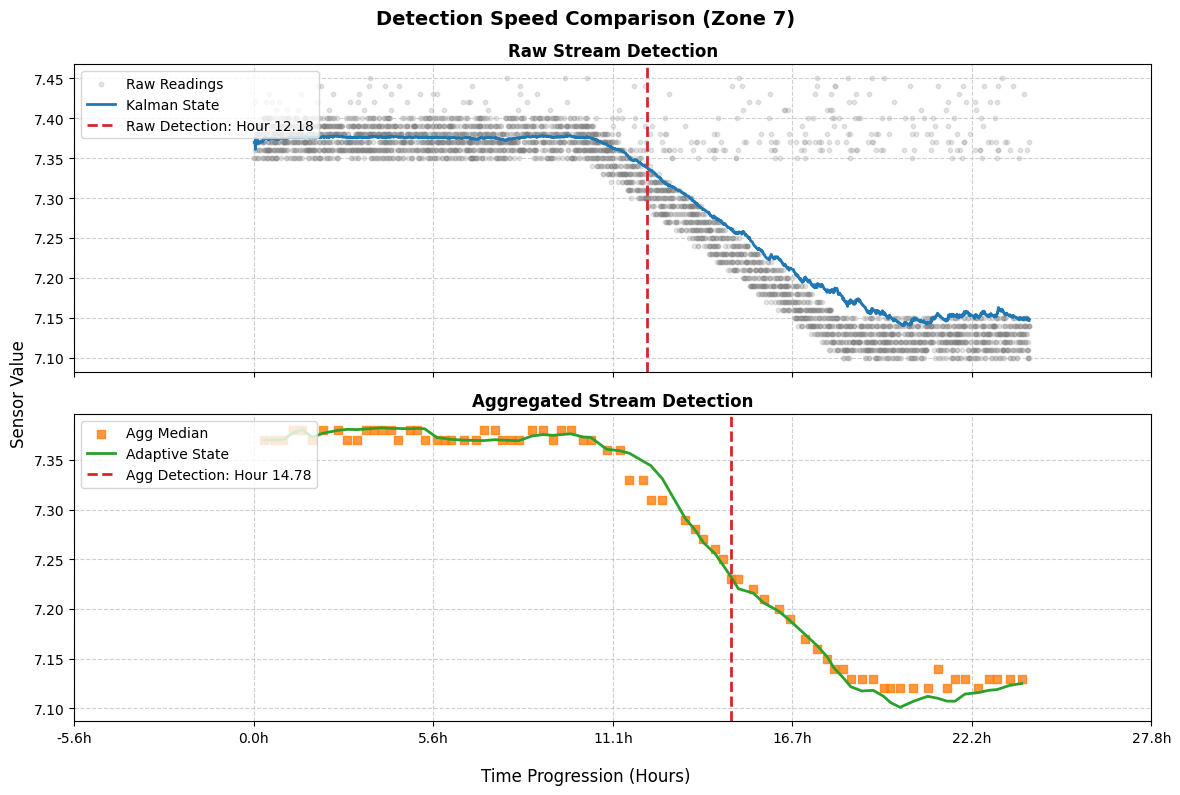

In [5]:
# 1. Initialize Parameters
TARGET_ZONE = 7          
ALPHA_NOISE = 0.3
BETA_ERROR = 0.10
TARGET_CONF = 70.0       
SAFE_START = 1800       # 30 minutes. Set to 86400 to simulate a completely healthy patient

print(f"--- 1. Running Disease Simulation (Stroke in Zone {TARGET_ZONE}) ---")
simulator = DiseaseSimulator()

raw_df, agg_df, t_start = simulator.run_single_disease(
    alpha=ALPHA_NOISE, 
    beta=BETA_ERROR, 
    disease_key='stroke_ph',
    target_confidence=TARGET_CONF,
    safe_start_time=SAFE_START
)

if agg_df is not None and not agg_df.empty:
    print(f"\n--- 2. Running Anomaly Detection ---")
    
    detector = AnomalyDetector(
        target_zone=TARGET_ZONE, 
        alpha=ALPHA_NOISE, 
        beta=BETA_ERROR,
        target_confidence=TARGET_CONF,
        raw_drift_threshold=3.5,
        agg_persistence=4,
        agg_abs_drift=0.10
    )

    processed_raw_df, det_raw = detector.detect_raw_stream(raw_df)
    processed_agg_df, det_agg = detector.detect_aggregated_stream(agg_df)

    print("\n--- Detection Results ---")
    print(f"Disease actually started at: Hour {t_start/3600:.2f}")
    
    # Calculate Delay for Raw Stream
    if det_raw:
        delay_raw = det_raw - t_start
        print(f"Raw Stream: Flagged at Hour {det_raw/3600:.2f}")
        if delay_raw < 0:
            print(f"   -> WARNING (False Positive): Detected {-delay_raw/60:.1f} minutes BEFORE onset.")
        else:
            print(f"   -> Delay: {delay_raw/60:.1f} minutes after onset.")
    else:
        print("Raw Stream: No anomaly detected.")
        
    # Calculate Delay for Aggregated Stream
    if det_agg:
        delay_agg = det_agg - t_start
        print(f"Aggregated Stream: Flagged at Hour {det_agg/3600:.2f}")
        if delay_agg < 0:
            print(f"   -> WARNING (False Positive): Detected {-delay_agg/60:.1f} minutes BEFORE onset.")
        else:
            print(f"   -> Delay: {delay_agg/60:.1f} minutes after onset.")
    else:
        print("Aggregated Stream: No anomaly detected.")

    print(f"\n--- 3. Generating Visualization ---")
    visualizer = AnomalyVisualizer()
    visualizer.plot_comparison(
        raw_df=processed_raw_df, 
        agg_df=processed_agg_df, 
        det_raw=det_raw, 
        det_agg=det_agg, 
        title=f"Detection Speed Comparison (Zone {TARGET_ZONE})"
    )

--- 1. Running Combined Disease Simulation (Pyelonephritis in Zone 16) ---
[PYELO_COMBINED] Safe Start Applied. Random Onset: Hour 7.1 | Peak: Hour 15.1

--- 2. Running Anomaly Detection ---

--- Detection Results ---
Disease actually started at: Hour 7.08

[AGGREGATED STREAM]
pH   Flagged at Hour 10.84 | Delay: 225.9 min
Temp Flagged at Hour 11.13 | Delay: 243.0 min

--- 3. Generating Visualization ---


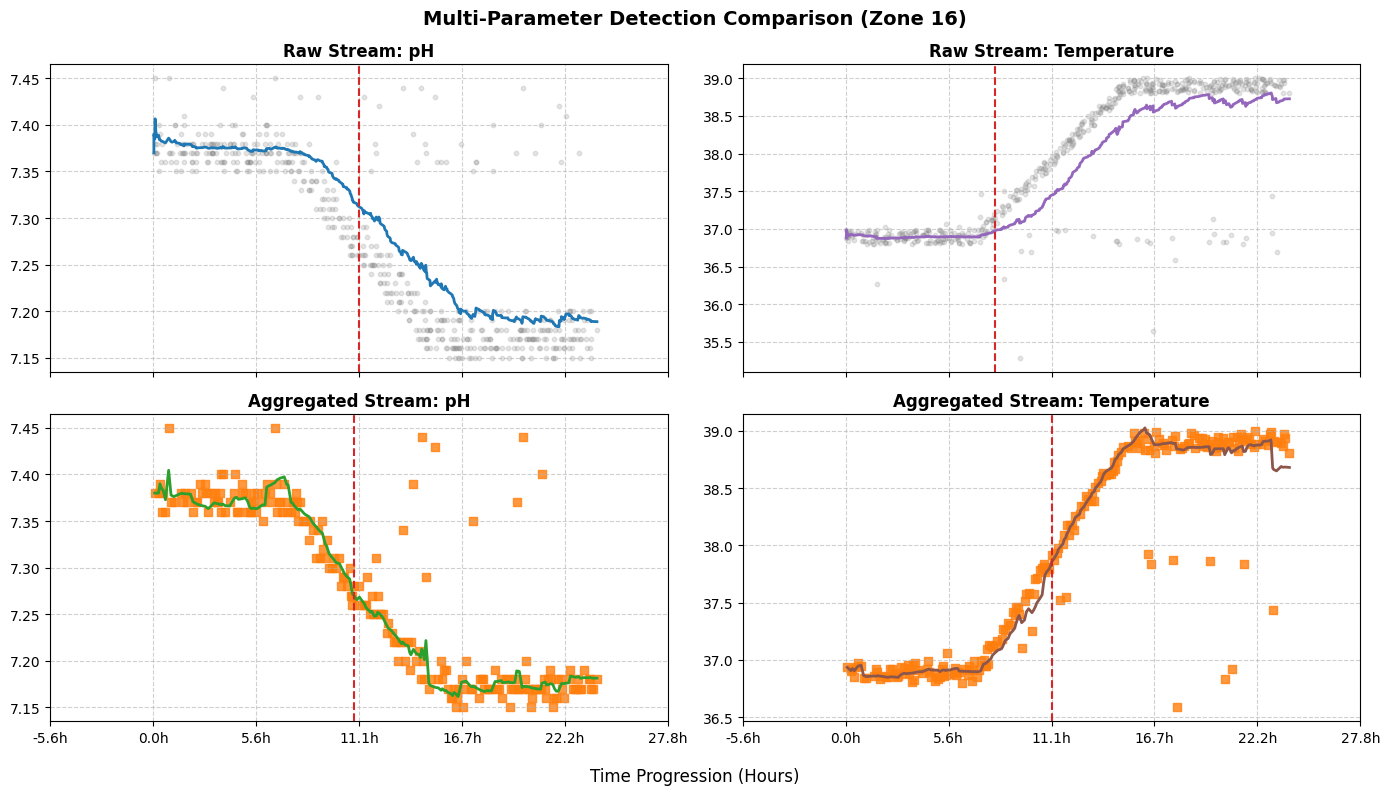

In [6]:
# 1. Initialize Parameters
TARGET_ZONE = 16         
ALPHA_NOISE = 0.05
BETA_ERROR = 0.10
TARGET_CONF = 70.0       
SAFE_START = 14400       

print(f"--- 1. Running Combined Disease Simulation (Pyelonephritis in Zone {TARGET_ZONE}) ---")
simulator = DiseaseSimulator()

raw_df, agg_df, t_start = simulator.run_combined_disease(
    alpha=ALPHA_NOISE, 
    beta=BETA_ERROR, 
    disease_key='pyelo_combined',
    target_confidence=TARGET_CONF,
    safe_start_time=SAFE_START
)

if agg_df is not None and not agg_df.empty:
    print(f"\n--- 2. Running Anomaly Detection ---")
    
    detector = AnomalyDetector(
        target_zone=TARGET_ZONE, 
        alpha=ALPHA_NOISE, 
        beta=BETA_ERROR,
        target_confidence=TARGET_CONF,
        agg_persistence=4,            # Require 4 bad packets in a row
        agg_abs_drift_ph=0.10,        # pH must deviate by at least 0.10
        agg_abs_drift_temp=0.8        # Temp must deviate by at least 0.8 degrees
    )

    processed_raw_df, det_raw = detector.detect_combined_raw_stream(raw_df)
    processed_agg_df, det_agg = detector.detect_combined_aggregated_stream(agg_df)

    print("\n--- Detection Results ---")
    print(f"Disease actually started at: Hour {t_start/3600:.2f}")
    
    def print_delay(param_name, det_time, t_start):
        if det_time:
            delay = det_time - t_start
            print(f"{param_name} Flagged at Hour {det_time/3600:.2f}", end=" | ")
            if delay < 0:
                print(f"False Positive ({-delay/60:.1f} min early)")
            else:
                print(f"Delay: {delay/60:.1f} min")
        else:
            print(f"{param_name} No anomaly detected.")
    
    print("\n[AGGREGATED STREAM]")
    print_delay("pH  ", det_agg['ph'], t_start)
    print_delay("Temp", det_agg['temp'], t_start)

    print(f"\n--- 3. Generating Visualization ---")
    visualizer = AnomalyVisualizer()
    visualizer.plot_combined_comparison(
        raw_df=processed_raw_df, 
        agg_df=processed_agg_df, 
        det_raw=det_raw, 
        det_agg=det_agg, 
        title=f"Multi-Parameter Detection Comparison (Zone {TARGET_ZONE})"
    )

--- 1. Running Disease Simulation (Stroke in Zone 7) ---
[STROKE_PH] Safe Start Applied. Random Onset: Hour 24.0 | Peak: Hour 32.0

--- 2. Running Anomaly Detection ---

--- Detection Results ---
Disease actually started at: Hour 24.00
Raw Stream: No anomaly detected.
Aggregated Stream: No anomaly detected.

--- 3. Generating Visualization ---


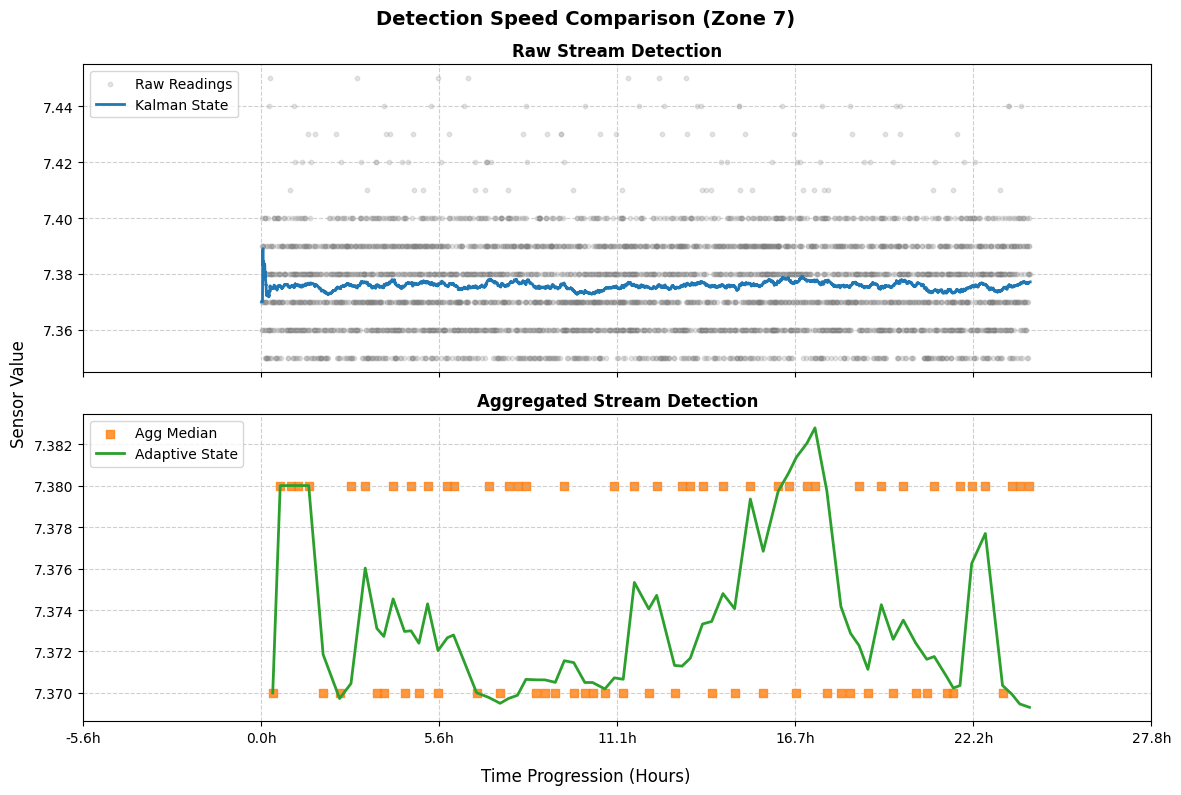

In [7]:
# 1. Initialize Parameters
TARGET_ZONE = 7          
ALPHA_NOISE = 0.3
BETA_ERROR = 0.10
TARGET_CONF = 70.0       
SAFE_START = 86400       # Set to 86400 to simulate a completely healthy patient

print(f"--- 1. Running Disease Simulation (Stroke in Zone {TARGET_ZONE}) ---")
simulator = DiseaseSimulator()

raw_df, agg_df, t_start = simulator.run_single_disease(
    alpha=ALPHA_NOISE, 
    beta=BETA_ERROR, 
    disease_key='stroke_ph',
    target_confidence=TARGET_CONF,
    safe_start_time=SAFE_START
)

if agg_df is not None and not agg_df.empty:
    print(f"\n--- 2. Running Anomaly Detection ---")
    
    detector = AnomalyDetector(
        target_zone=TARGET_ZONE, 
        alpha=ALPHA_NOISE, 
        beta=BETA_ERROR,
        target_confidence=TARGET_CONF
    )

    processed_raw_df, det_raw = detector.detect_raw_stream(raw_df)
    processed_agg_df, det_agg = detector.detect_aggregated_stream(agg_df)

    print("\n--- Detection Results ---")
    print(f"Disease actually started at: Hour {t_start/3600:.2f}")
    
    # Calculate Delay for Raw Stream
    if det_raw:
        delay_raw = det_raw - t_start
        print(f"Raw Stream: Flagged at Hour {det_raw/3600:.2f}")
        if delay_raw < 0:
            print(f"   -> WARNING (False Positive): Detected {-delay_raw/60:.1f} minutes BEFORE onset.")
        else:
            print(f"   -> Delay: {delay_raw/60:.1f} minutes after onset.")
    else:
        print("Raw Stream: No anomaly detected.")
        
    # Calculate Delay for Aggregated Stream
    if det_agg:
        delay_agg = det_agg - t_start
        print(f"Aggregated Stream: Flagged at Hour {det_agg/3600:.2f}")
        if delay_agg < 0:
            print(f"   -> WARNING (False Positive): Detected {-delay_agg/60:.1f} minutes BEFORE onset.")
        else:
            print(f"   -> Delay: {delay_agg/60:.1f} minutes after onset.")
    else:
        print("Aggregated Stream: No anomaly detected.")

    print(f"\n--- 3. Generating Visualization ---")
    visualizer = AnomalyVisualizer()
    visualizer.plot_comparison(
        raw_df=processed_raw_df, 
        agg_df=processed_agg_df, 
        det_raw=det_raw, 
        det_agg=det_agg, 
        title=f"Detection Speed Comparison (Zone {TARGET_ZONE})"
    )

--- 1. Running Combined Disease Simulation (Pyelonephritis in Zone 16) ---
[PYELO_COMBINED] Safe Start Applied. Random Onset: Hour 24.0 | Peak: Hour 32.0

--- 2. Running Anomaly Detection ---

--- Detection Results ---
Disease actually started at: Hour 24.00

[AGGREGATED STREAM]
pH   No anomaly detected.
Temp No anomaly detected.

--- 3. Generating Visualization ---


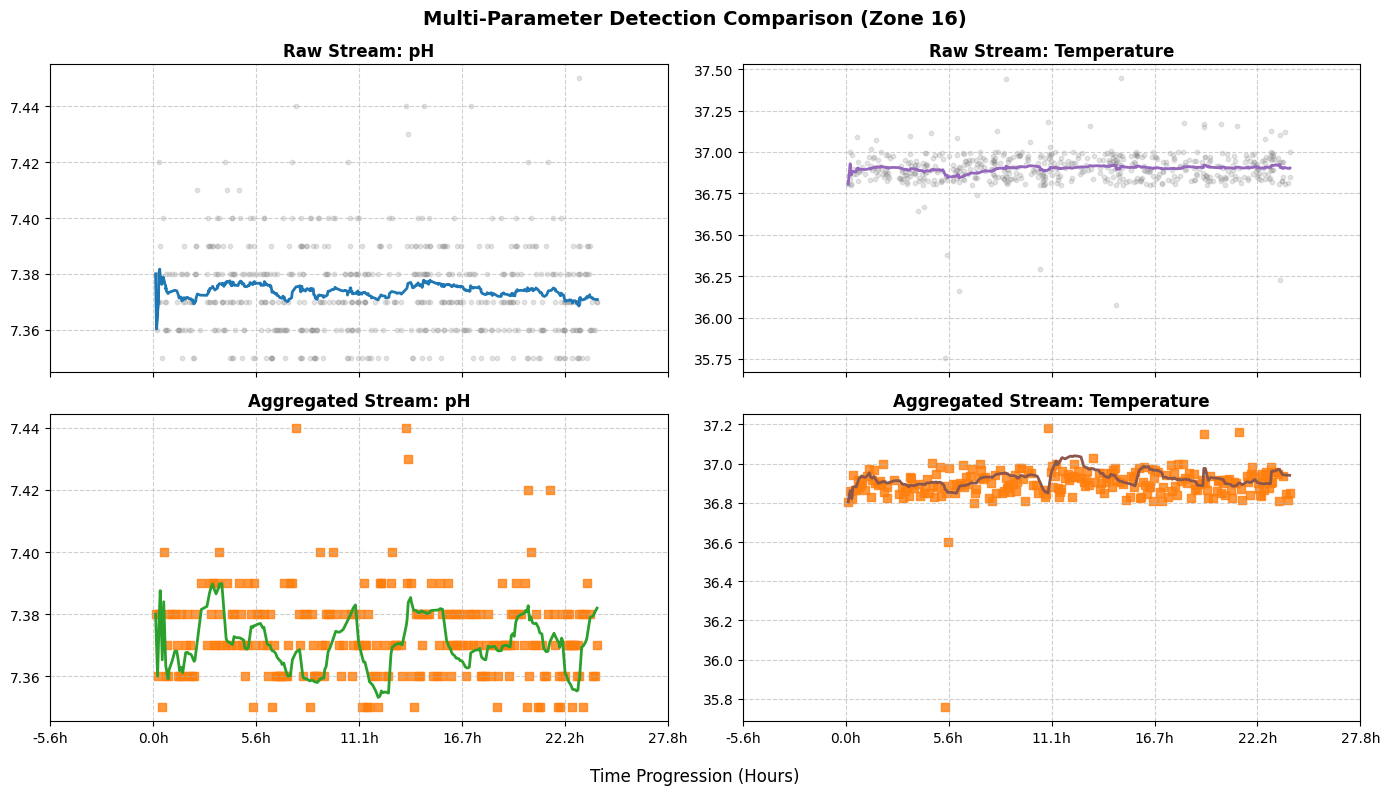

In [8]:
# 1. Initialize Parameters
TARGET_ZONE = 16         
ALPHA_NOISE = 0.05
BETA_ERROR = 0.10
TARGET_CONF = 70.0       
SAFE_START = 86400       

print(f"--- 1. Running Combined Disease Simulation (Pyelonephritis in Zone {TARGET_ZONE}) ---")
simulator = DiseaseSimulator()

raw_df, agg_df, t_start = simulator.run_combined_disease(
    alpha=ALPHA_NOISE, 
    beta=BETA_ERROR, 
    disease_key='pyelo_combined',
    target_confidence=TARGET_CONF,
    safe_start_time=SAFE_START
)

if agg_df is not None and not agg_df.empty:
    print(f"\n--- 2. Running Anomaly Detection ---")
    
    detector = AnomalyDetector(
        target_zone=TARGET_ZONE, 
        alpha=ALPHA_NOISE, 
        beta=BETA_ERROR,
        target_confidence=TARGET_CONF,
        agg_persistence=4,            # Require 4 bad packets in a row
        agg_abs_drift_ph=0.10,        # pH must deviate by at least 0.10
        agg_abs_drift_temp=0.8        # Temp must deviate by at least 0.8 degrees
    )

    processed_raw_df, det_raw = detector.detect_combined_raw_stream(raw_df)
    processed_agg_df, det_agg = detector.detect_combined_aggregated_stream(agg_df)

    print("\n--- Detection Results ---")
    print(f"Disease actually started at: Hour {t_start/3600:.2f}")
    
    def print_delay(param_name, det_time, t_start):
        if det_time:
            delay = det_time - t_start
            print(f"{param_name} Flagged at Hour {det_time/3600:.2f}", end=" | ")
            if delay < 0:
                print(f"False Positive ({-delay/60:.1f} min early)")
            else:
                print(f"Delay: {delay/60:.1f} min")
        else:
            print(f"{param_name} No anomaly detected.")
    
    print("\n[AGGREGATED STREAM]")
    print_delay("pH  ", det_agg['ph'], t_start)
    print_delay("Temp", det_agg['temp'], t_start)

    print(f"\n--- 3. Generating Visualization ---")
    visualizer = AnomalyVisualizer()
    visualizer.plot_combined_comparison(
        raw_df=processed_raw_df, 
        agg_df=processed_agg_df, 
        det_raw=det_raw, 
        det_agg=det_agg, 
        title=f"Multi-Parameter Detection Comparison (Zone {TARGET_ZONE})"
    )